# Olist: which orders are likely to arrive late?

**Question.** My SQL project found that 8.11% of delivered Olist orders arrive late and that late orders get 2.57 stars vs 4.29. Here I ask the next question: **what is known at purchase time that predicts a late delivery, and can it be used to act before the order ships?**

**Data.** Public Olist e-commerce dataset (Kaggle, ~100k orders, 2016-2018): orders, customers, items, sellers, products, geolocation.
**Definition.** An order is *late* if `order_delivered_customer_date` is after `order_estimated_delivery_date` (same rule as the SQL project).
**Tools.** Python, pandas, matplotlib, scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
DATA = '../data/'
FIG = 'figures/'

## 1. Load the tables and check that the SQL numbers reproduce

In [2]:
orders = pd.read_csv(DATA + 'olist_orders_dataset.csv',
                     parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date',
                                  'order_estimated_delivery_date'])
customers = pd.read_csv(DATA + 'olist_customers_dataset.csv')
items     = pd.read_csv(DATA + 'olist_order_items_dataset.csv')
sellers   = pd.read_csv(DATA + 'olist_sellers_dataset.csv')
products  = pd.read_csv(DATA + 'olist_products_dataset.csv')
geo       = pd.read_csv(DATA + 'olist_geolocation_dataset.csv')

# delivered orders that have a delivery date
d = orders[orders.order_status == 'delivered'].dropna(subset=['order_delivered_customer_date']).copy()
d['late'] = (d.order_delivered_customer_date > d.order_estimated_delivery_date).astype(int)
print(f'delivered orders: {len(d):,}   late: {d.late.sum():,}   late rate: {d.late.mean():.2%}')

delivered orders: 96,470   late: 7,826   late rate: 8.11%


The delivered-order count (96,470) and the late rate (8.11%) match the SQL project, so the two analyses use the same definition.

## 2. Build one row per order (only information known at purchase time)

Features: distance between seller and customer, same-state flag, promised delivery days, product weight and volume, freight, price, number of items and sellers, purchase month and weekday, and the two states.
I deliberately **exclude anything that happens after purchase** (carrier hand-over date, actual delivery time), otherwise the model would just read the answer.

In [3]:
# average coordinates per zip prefix (geolocation has many rows per prefix)
geo = geo.groupby('geolocation_zip_code_prefix').agg(lat=('geolocation_lat', 'mean'),
                                                     lng=('geolocation_lng', 'mean')).reset_index()

# item-level product size, then one row per order
items = items.merge(products[['product_id', 'product_weight_g', 'product_length_cm',
                              'product_height_cm', 'product_width_cm']], on='product_id', how='left')
items['volume'] = items.product_length_cm * items.product_height_cm * items.product_width_cm
main_seller = (items.sort_values(['order_id', 'order_item_id'])
                    .groupby('order_id').first().reset_index()[['order_id', 'seller_id']])
per_order = items.groupby('order_id').agg(n_items=('order_item_id', 'count'),
                                          n_sellers=('seller_id', 'nunique'),
                                          price=('price', 'sum'), freight=('freight_value', 'sum'),
                                          weight=('product_weight_g', 'sum'),
                                          volume=('volume', 'sum')).reset_index()

d = (d.merge(customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id')
      .merge(per_order, on='order_id').merge(main_seller, on='order_id')
      .merge(sellers, on='seller_id'))
d = d.merge(geo.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                'lat': 'c_lat', 'lng': 'c_lng'}), on='customer_zip_code_prefix', how='left')
d = d.merge(geo.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                'lat': 's_lat', 'lng': 's_lng'}), on='seller_zip_code_prefix', how='left')

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

d['km'] = haversine_km(d.s_lat, d.s_lng, d.c_lat, d.c_lng)
d['promised_days'] = (d.order_estimated_delivery_date - d.order_purchase_timestamp).dt.total_seconds() / 86400
d['delivered_days'] = (d.order_delivered_customer_date - d.order_purchase_timestamp).dt.total_seconds() / 86400
d['same_state'] = (d.seller_state == d.customer_state).astype(int)
d['multi_seller'] = (d.n_sellers > 1).astype(int)
d['freight_ratio'] = d.freight / (d.price + 1)
d['month'] = d.order_purchase_timestamp.dt.month.astype(str)
d['dow'] = d.order_purchase_timestamp.dt.dayofweek.astype(str)
for col in ['km', 'weight', 'volume']:
    d['log_' + col] = np.log1p(d[col])

# 2016 has only ~270 delivered orders, too few to learn from
d = d[d.order_purchase_timestamp >= '2017-01-01'].copy()
print(f'orders used: {len(d):,}   late rate: {d.late.mean():.2%}')

orders used: 96,203   late rate: 8.13%


## 3. What does lateness look like?

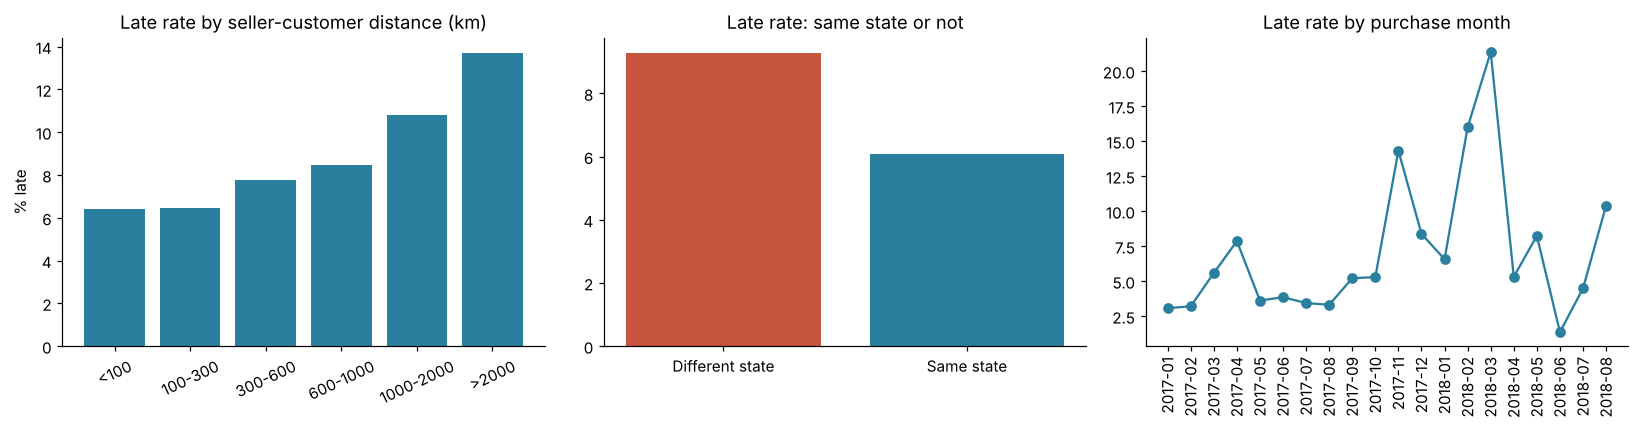

km
<100          6.4
100-300       6.5
300-600       7.8
600-1000      8.5
1000-2000    10.8
>2000        13.7
same_state
0    9.3
1    6.1
order_purchase_timestamp
2018-03    21.4
2018-02    16.0
2017-11    14.3
2018-08    10.4
Freq: M


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

bands = pd.cut(d.km, [0, 100, 300, 600, 1000, 2000, 9000],
               labels=['<100', '100-300', '300-600', '600-1000', '1000-2000', '>2000'])
by_km = d.groupby(bands, observed=True).late.mean() * 100
ax[0].bar(by_km.index.astype(str), by_km.values, color='#2a7f9e')
ax[0].set_title('Late rate by seller-customer distance (km)'); ax[0].set_ylabel('% late'); ax[0].tick_params(axis='x', rotation=25)

by_same = d.groupby('same_state').late.mean() * 100
ax[1].bar(['Different state', 'Same state'], by_same.values, color=['#c8553d', '#2a7f9e'])
ax[1].set_title('Late rate: same state or not')

by_month = d.groupby(d.order_purchase_timestamp.dt.to_period('M')).late.mean() * 100
ax[2].plot(by_month.index.astype(str), by_month.values, marker='o', color='#2a7f9e')
ax[2].set_title('Late rate by purchase month'); ax[2].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.savefig(FIG + '01_eda.png'); plt.show()

print(by_km.round(1).to_string()); print(by_same.round(1).to_string())
print(by_month.sort_values(ascending=False).head(4).round(1).to_string())

- Late rate rises steadily with distance, and orders shipped within the same state are late less often.
- The monthly chart has sharp spikes (e.g. Nov 2017 and Feb-Mar 2018). Distance and size cannot explain those, so part of lateness is driven by **time-specific events** that purchase-time features cannot see. The dataset does not say why.

## 4. Model: logistic regression

Logistic regression because it is **explainable** (each feature has an odds ratio). A gradient-boosting model is trained only as a benchmark to see how much accuracy simplicity costs.
Metric: ROC-AUC (ranking quality) and the late rate in the highest-risk decile (what a business would act on). The late class is only ~8%, so accuracy would be misleading.

In [5]:
num = ['log_km', 'promised_days', 'log_weight', 'log_volume', 'freight', 'price',
       'n_items', 'multi_seller', 'same_state', 'freight_ratio']
cat = ['customer_state', 'seller_state', 'month', 'dow']
X, y = d[num + cat], d.late

def make_pipeline(model):
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=200, sparse_output=False), cat)])
    return Pipeline([('pre', pre), ('model', model)])

tr, te = train_test_split(X.index, test_size=0.25, stratify=y, random_state=42)
logit = make_pipeline(LogisticRegression(max_iter=2000)).fit(X.loc[tr], y[tr])
hgb   = make_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0)).fit(X.loc[tr], y[tr])

def decile_table(y_true, p):
    t = pd.DataFrame({'late': y_true.values, 'p': p})
    t['decile'] = pd.qcut(t.p.rank(method='first'), 10, labels=False) + 1   # 10 = highest risk
    return t

results = {}
for name, m in [('Logistic regression', logit), ('Gradient boosting (benchmark)', hgb)]:
    p = m.predict_proba(X.loc[te])[:, 1]
    t = decile_table(y[te], p)
    results[name] = p
    print(f"{name:32s} ROC-AUC {roc_auc_score(y[te], p):.3f} | PR-AUC {average_precision_score(y[te], p):.3f} "
          f"(random = {y[te].mean():.3f}) | late rate, top decile {t[t.decile==10].late.mean():.1%}, "
          f"bottom decile {t[t.decile==1].late.mean():.1%}")

Logistic regression              ROC-AUC 0.756 | PR-AUC 0.248 (random = 0.081) | late rate, top decile 27.9%, bottom decile 1.5%


Gradient boosting (benchmark)    ROC-AUC 0.782 | PR-AUC 0.293 (random = 0.081) | late rate, top decile 32.1%, bottom decile 0.9%


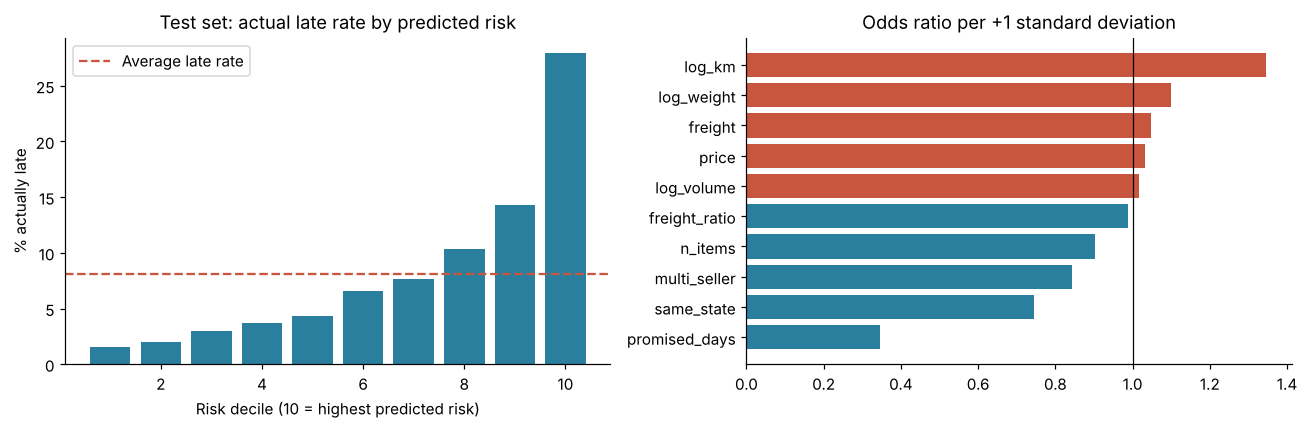

Top decile catches 34% of all late orders; top two deciles catch 52%.
promised_days    0.35
same_state       0.74
multi_seller     0.84
n_items          0.90
freight_ratio    0.99
log_volume       1.02
price            1.03
freight          1.05
log_weight       1.10
log_km           1.34


In [6]:
p = results['Logistic regression']
t = decile_table(y[te], p)
rate = t.groupby('decile').late.mean() * 100
caught = t[t.decile == 10].late.sum() / t.late.sum()
caught2 = t[t.decile >= 9].late.sum() / t.late.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(rate.index, rate.values, color='#2a7f9e')
ax[0].axhline(y[te].mean() * 100, color='#c8553d', ls='--', label='Average late rate')
ax[0].set_xlabel('Risk decile (10 = highest predicted risk)'); ax[0].set_ylabel('% actually late')
ax[0].set_title('Test set: actual late rate by predicted risk'); ax[0].legend()

names = logit.named_steps['pre'].get_feature_names_out()
coef = pd.Series(logit.named_steps['model'].coef_[0], index=names)
odds = np.exp(coef[[n for n in names if n.startswith('num__')]]).sort_values()
odds.index = [i.replace('num__', '') for i in odds.index]
ax[1].barh(odds.index, odds.values, color=['#2a7f9e' if v < 1 else '#c8553d' for v in odds.values])
ax[1].axvline(1, color='black', lw=0.8); ax[1].set_title('Odds ratio per +1 standard deviation')
plt.tight_layout(); plt.savefig(FIG + '02_model.png'); plt.show()

print(f'Top decile catches {caught:.0%} of all late orders; top two deciles catch {caught2:.0%}.')
print(odds.round(2).to_string())

Reading the odds ratios (all else equal, for +1 standard deviation):
- **Longer distance** raises the odds of being late; **same state** lowers them.
- **Longer promised delivery time** lowers the odds strongly (the promise already includes a buffer); this is the lever the next section uses.
- Heavier and costlier-to-ship orders are slightly riskier.

### Does it hold over time? (honest check)
A random split mixes months. In reality the model would be used on *future* orders, so I also train on orders before April 2018 and test on April 2018 onward.

In [7]:
cut = pd.Timestamp('2018-04-01')
tr_t = X.index[d.order_purchase_timestamp < cut]; te_t = X.index[d.order_purchase_timestamp >= cut]
m_t = make_pipeline(LogisticRegression(max_iter=2000)).fit(X.loc[tr_t], y[tr_t])
p_t = m_t.predict_proba(X.loc[te_t])[:, 1]; t_t = decile_table(y[te_t], p_t)
print(f'train late rate {y[tr_t].mean():.1%} | test late rate {y[te_t].mean():.1%}')
print(f'ROC-AUC {roc_auc_score(y[te_t], p_t):.3f} | late rate top decile {t_t[t_t.decile==10].late.mean():.1%}, '
      f'bottom decile {t_t[t_t.decile==1].late.mean():.1%}')

train late rate 9.2% | test late rate 6.0%
ROC-AUC 0.675 | late rate top decile 14.4%, bottom decile 0.7%


Performance drops on future orders: the model still **ranks** risk (top decile is clearly worse than the bottom), but it is weaker, because late spikes depend on events that are not in the data. It should be used as a **risk ranking**, not as an exact prediction.

## 5. From model to decision: what to do with the riskiest orders?

The model ranks orders at purchase time. One action available at that moment is the **delivery promise**. If the riskiest 10% of orders get a longer promised date, fewer of them are late *by the customer's definition*.
This is a scenario using the test set: actual delivery times are kept as they were, and only the promised date moves.

 extra days promised to top-risk 10%  late rate of top-risk 10%  overall late rate
                                   0                       27.9                8.1
                                   2                       22.4                7.6
                                   3                       20.4                7.4
                                   5                       17.7                7.1
                                   7                       14.7                6.8


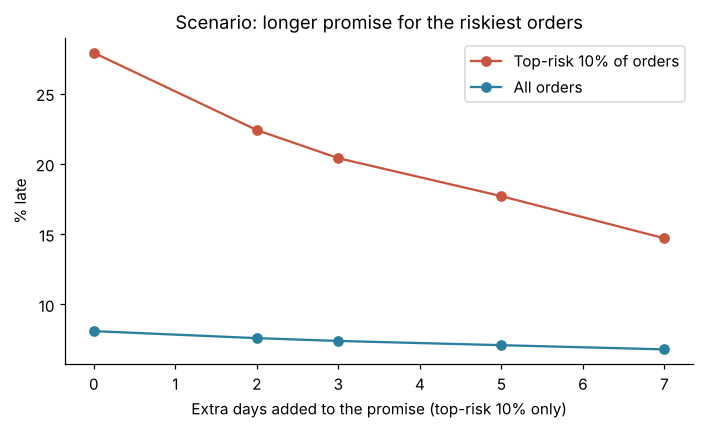

In [8]:
T = d.loc[te].copy(); T['risk'] = results['Logistic regression']
T['decile'] = pd.qcut(T.risk.rank(method='first'), 10, labels=False) + 1
top = T[T.decile == 10]

rows = []
for b in [0, 2, 3, 5, 7]:
    new_late = np.where(T.decile == 10, T.delivered_days > T.promised_days + b, T.late == 1)
    rows.append({'extra days promised to top-risk 10%': b,
                 'late rate of top-risk 10%': (top.delivered_days > top.promised_days + b).mean() * 100,
                 'overall late rate': new_late.mean() * 100})
scen = pd.DataFrame(rows).round(1)
print(scen.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(scen.iloc[:, 0], scen.iloc[:, 1], marker='o', color='#c8553d', label='Top-risk 10% of orders')
ax.plot(scen.iloc[:, 0], scen.iloc[:, 2], marker='o', color='#2a7f9e', label='All orders')
ax.set_xlabel('Extra days added to the promise (top-risk 10% only)'); ax.set_ylabel('% late')
ax.set_title('Scenario: longer promise for the riskiest orders'); ax.legend()
plt.tight_layout(); plt.savefig(FIG + '03_scenario.png'); plt.show()

In [9]:
# Which routes (seller state -> customer state) are riskiest, with enough orders to matter?
routes = d.groupby(['seller_state', 'customer_state']).late.agg(rate='mean', orders='size')
routes = routes[routes.orders >= 300].sort_values('rate', ascending=False)
routes['rate'] = (routes.rate * 100).round(1)
print(routes.head(8).to_string())

                             rate  orders
seller_state customer_state              
SP           MA              21.1     488
             PI              18.3     328
             RJ              15.5    8141
             CE              15.3     966
             BA              15.0    2304
             MS              14.7     477
             ES              14.2    1460
PR           RJ              14.1     960


## 6. Findings and recommendation

*(Numbers below come from the cells above.)*
- **The model ranks risk usefully:** on held-out orders, the highest-risk 10% are late far more often than average and the lowest-risk 10% almost never are; the top decile catches about a third of all late orders and the top two deciles about half.
- **Main drivers:** distance, cross-state shipping and a short promised delivery time.
- **Biggest route by volume:** São Paulo to Rio de Janeiro is late more often than the average route, which agrees with the SQL project's recommendation to fix Rio de Janeiro first.

**Recommendation.** At purchase time, give the riskiest 10% of orders a longer promised date. In the scenario, adding 5 days to that group lowers the overall late rate from 8.1% to about 7.1%, without changing a single shipment. This is a scenario, not a measured result: customers may react to longer promises, so it should be tested as an A/B experiment before rollout.

## 7. Limitations
- Observational data from 2017-2018; no cause is proven (e.g. the monthly spikes are unexplained).
- Predictive power falls on future periods (time-split check above).
- Distance uses zip-prefix averages, not real routes.
- The scenario assumes delivery times and demand stay the same.